# Task 3: Feature Selection for SVM using RFE
Use feature selection to improve SVM performance by removing redundant features, applying Recursive Feature Elimination (RFE) and testing different feature subsets.

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, f1_score

## Step 2: Load and prepare the data

In [2]:
df = pd.read_csv("employee_data_1.csv")

# fill missing values with median
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].median())
df["Training_Hours"] = df["Training_Hours"].fillna(df["Training_Hours"].median())

# target: High = 1, Low = 0
df["Satisfaction"] = df["Satisfaction"].map({"Low": 0, "High": 1})

# text columns -> numbers
df = pd.get_dummies(df, columns=["Department", "Education", "City_Tier"], drop_first=True)

X = df.drop("Satisfaction", axis=1)
y = df["Satisfaction"]
print("Features:", X.shape[1])
df.head()

Features: 18


,Age,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_Diploma,Education_Masters,Education_PhD,City_Tier_Tier2,City_Tier_Tier3
0,41,17,2.4,42.0,56.0,0,5.0,25.00,1,False,False,True,False,False,False,False,True,True,False
1,39,13,3.7,49.0,12.0,2,3.1,19.41,0,False,False,False,False,True,False,False,False,False,False
2,24,2,3.5,45.0,8.0,2,3.9,8.41,0,False,False,False,True,False,True,False,False,False,True
3,26,0,3.7,34.0,5.0,1,4.0,19.83,0,True,False,False,False,False,False,True,False,False,False
4,44,19,3.8,40.0,56.0,0,3.2,28.35,1,False,False,False,False,False,False,False,False,True,False


## Step 3: Split and scale the data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SVM and Logistic Regression need scaled data
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn scaling only from train data
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, " Test:", X_test_s.shape)

Train: (1600, 18)  Test: (400, 18)


## Step 4: Check redundant features with a correlation heatmap
Features that are highly correlated with each other give the same information.

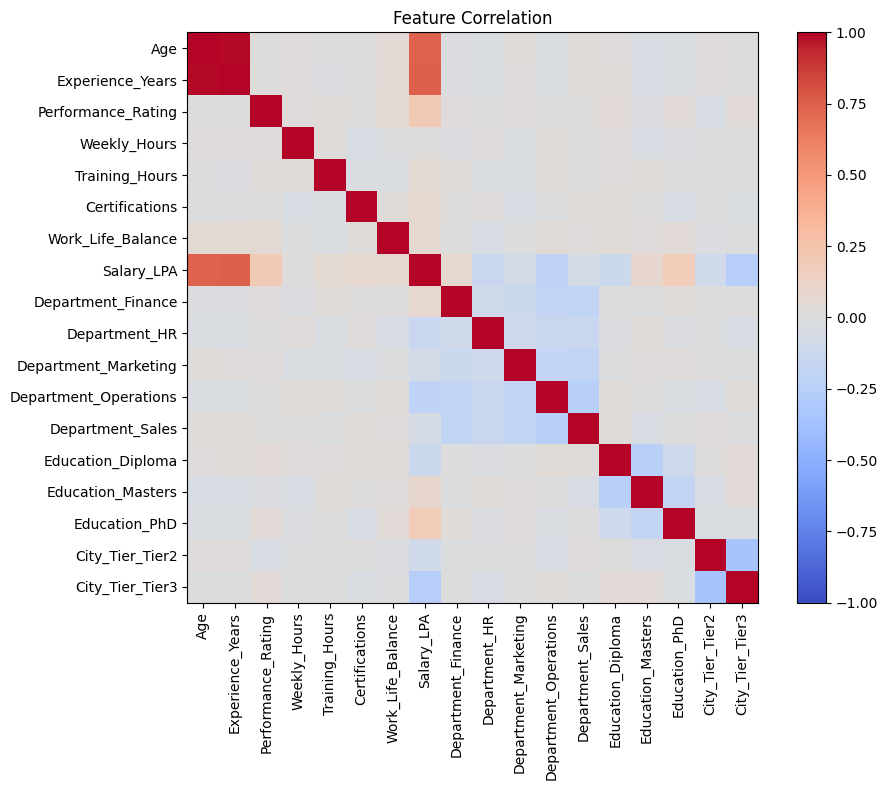

In [4]:
corr = X.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

In [5]:
# list pairs with correlation above 0.8
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.8:
            print(corr.columns[i], "and", corr.columns[j], "->", round(corr.iloc[i, j], 3))

Age and Experience_Years -> 0.988


Age and Experience_Years have a correlation of about 0.99, so they give almost the same information and one of them is redundant.

## Step 5: SVM with all features (baseline)

In [6]:
svm_all = SVC(kernel="rbf", C=1, class_weight="balanced", random_state=42)
svm_all.fit(X_train_s, y_train)
pred_all = svm_all.predict(X_test_s)

base_acc = accuracy_score(y_test, pred_all)
base_f1 = f1_score(y_test, pred_all)
print("All", X.shape[1], "features")
print("Accuracy:", round(base_acc, 4))
print("F1-score:", round(base_f1, 4))

All 18 features
Accuracy: 0.795
F1-score: 0.672


## Step 6: Apply RFE
RFE removes the weakest feature one by one. It needs a model that gives feature weights, so I use an SVM with a **linear kernel** for the ranking.

In [7]:
linear_svm = SVC(kernel="linear", class_weight="balanced", random_state=42)

rfe = RFE(estimator=linear_svm, n_features_to_select=1, step=1)
rfe.fit(X_train_s, y_train)

ranking = pd.DataFrame({
    "Feature": X.columns,
    "Rank": rfe.ranking_,
}).sort_values("Rank")

ranking.reset_index(drop=True)

,Feature,Rank
0,Salary_LPA,1
1,Work_Life_Balance,2
2,Weekly_Hours,3
3,Performance_Rating,4
4,Age,5
5,City_Tier_Tier2,6
6,Department_HR,7
7,Department_Sales,8
8,Department_Marketing,9
9,Education_Diploma,10


Rank 1 is the most important feature and the highest rank number is the first one removed.

## Step 7: Test different numbers of features
I take the top-k features from the RFE ranking and train the rbf SVM on each subset using 5-fold cross validation and the test data.

In [8]:
ordered_features = list(ranking["Feature"])   # best to worst
subset_rows = []

for k in range(1, len(ordered_features) + 1):
    chosen = ordered_features[:k]
    idx = [list(X.columns).index(f) for f in chosen]   # column positions

    model = SVC(kernel="rbf", C=1, class_weight="balanced", random_state=42)
    cv_f1 = cross_val_score(model, X_train_s[:, idx], y_train, cv=5, scoring="f1").mean()

    model.fit(X_train_s[:, idx], y_train)
    pred = model.predict(X_test_s[:, idx])

    subset_rows.append({
        "Num Features": k,
        "CV F1": cv_f1,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
    })

subset_df = pd.DataFrame(subset_rows)
subset_df.round(4)

,Num Features,CV F1,Test Accuracy,Test F1
0,1,0.5875,0.7150,0.5778
1,2,0.6786,0.7800,0.6692
2,3,0.7069,0.7550,0.6475
3,4,0.7056,0.7825,0.6742
4,5,0.7023,0.7950,0.6822
5,6,0.7098,0.7925,0.6795
6,7,0.7059,0.7925,0.6770
7,8,0.7059,0.7950,0.6797
8,9,0.7148,0.8025,0.6926
9,10,0.7113,0.8075,0.6957


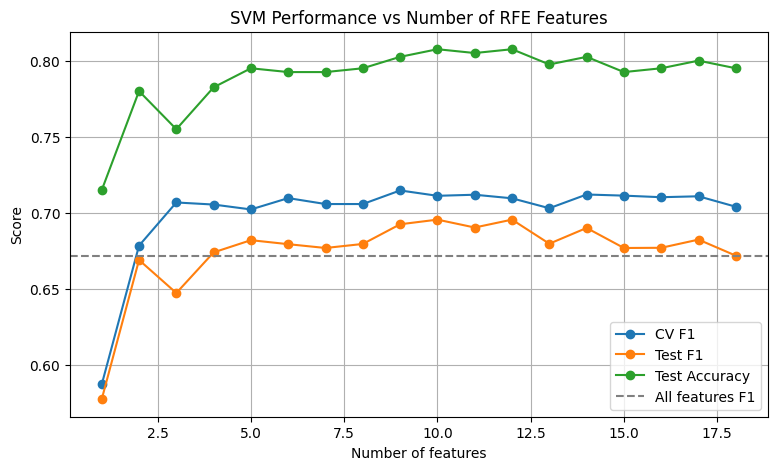

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(subset_df["Num Features"], subset_df["CV F1"], marker="o", label="CV F1")
plt.plot(subset_df["Num Features"], subset_df["Test F1"], marker="o", label="Test F1")
plt.plot(subset_df["Num Features"], subset_df["Test Accuracy"], marker="o", label="Test Accuracy")
plt.axhline(base_f1, color="gray", linestyle="--", label="All features F1")
plt.xlabel("Number of features")
plt.ylabel("Score")
plt.title("SVM Performance vs Number of RFE Features")
plt.legend()
plt.grid(True)
plt.show()

## Step 8: Choose the best subset
I pick the number of features with the best cross validation F1 (not the test data, so the test set stays fair).

In [10]:
best_k = int(subset_df.loc[subset_df["CV F1"].idxmax(), "Num Features"])
selected = ordered_features[:best_k]

print("Best number of features:", best_k)
print("Selected features:", selected)
print("Removed features :", [f for f in X.columns if f not in selected])

Best number of features: 9
Selected features: ['Salary_LPA', 'Work_Life_Balance', 'Weekly_Hours', 'Performance_Rating', 'Age', 'City_Tier_Tier2', 'Department_HR', 'Department_Sales', 'Department_Marketing']
Removed features : ['Experience_Years', 'Training_Hours', 'Certifications', 'Department_Finance', 'Department_Operations', 'Education_Diploma', 'Education_Masters', 'Education_PhD', 'City_Tier_Tier3']


## Step 9: Compare other feature subsets
I also try a few manual subsets to compare with the RFE subset.

In [11]:
numeric_only = ["Age", "Experience_Years", "Performance_Rating", "Weekly_Hours",
                "Training_Hours", "Certifications", "Work_Life_Balance", "Salary_LPA"]
no_age = [c for c in X.columns if c != "Age"]          # remove one of the correlated pair

subsets = {
    "All features": list(X.columns),
    "RFE selected": selected,
    "Numeric only": numeric_only,
    "Without Age": no_age,
}

rows = []
for name, cols in subsets.items():
    idx = [list(X.columns).index(c) for c in cols]
    model = SVC(kernel="rbf", C=1, class_weight="balanced", random_state=42)
    model.fit(X_train_s[:, idx], y_train)
    pred = model.predict(X_test_s[:, idx])
    rows.append({
        "Subset": name,
        "Num Features": len(cols),
        "Accuracy": accuracy_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

final_df = pd.DataFrame(rows).set_index("Subset")
final_df.round(4)

,Num Features,Accuracy,F1-score
Subset,,,
All features,18,0.7950,0.6720
RFE selected,9,0.8025,0.6926
Numeric only,8,0.7875,0.6743
Without Age,17,0.7975,0.6798


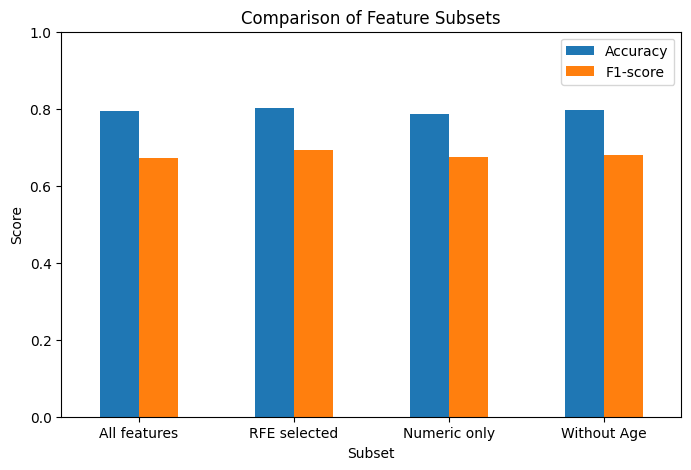

In [12]:
final_df[["Accuracy", "F1-score"]].plot(kind="bar", figsize=(8, 5))
plt.title("Comparison of Feature Subsets")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

## Conclusion
- Age and Experience_Years are almost the same feature (correlation 0.99), and RFE kept Age but removed Experience_Years.
- The CV F1-score stays almost flat (about 0.70 to 0.71) once 3 or more features are used, so many features can be removed without losing performance.
- The best subset by cross validation had 9 features. On the test data it gave accuracy 0.8025 and F1 0.6926 compared to 0.795 and 0.672 with all 18 features. The improvement is small, but the model is simpler with half the features.
- The subset was chosen using cross validation only, so the test data was not used for choosing features. Note that RFE used a linear SVM for ranking and the final model uses rbf, so the ranking is an approximation for the rbf model.